## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

## Dataset Loading and Initial Inspection

In [2]:
df=pd.read_csv('pipeline_corrosion.csv')
df

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8435,SEG-0250,2022-06-25,19,10.48,X42,609.6,9.50,CTE,1,crude_oil,...,0.0838,0.058,0.745214,0.169667,-0.0725,4098.40,31510.77,4.22464,4002.8200,208.0
8436,SEG-0250,2023-02-17,20,11.13,X42,609.6,9.50,CTE,1,crude_oil,...,0.2251,-0.527,-6.721081,0.169233,0.1181,5041.14,36056.76,5.30400,4112.2325,237.0
8437,SEG-0250,2023-09-06,21,11.68,X42,609.6,9.50,CTE,1,crude_oil,...,0.1782,0.294,4.019688,0.147433,-0.1110,3582.78,35333.44,5.35602,4514.1200,201.0
8438,SEG-0250,2024-04-29,22,12.33,X42,609.6,9.50,CTE,1,crude_oil,...,0.1057,-0.453,-5.954259,0.187900,0.1143,4703.10,34608.60,6.38365,4622.5325,236.0


In [3]:
df.head()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0


In [4]:
df.tail()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
8435,SEG-0250,2022-06-25,19,10.48,X42,609.6,9.5,CTE,1,crude_oil,...,0.0838,0.058,0.745214,0.169667,-0.0725,4098.40,31510.77,4.22464,4002.8200,208.0
8436,SEG-0250,2023-02-17,20,11.13,X42,609.6,9.5,CTE,1,crude_oil,...,0.2251,-0.527,-6.721081,0.169233,0.1181,5041.14,36056.76,5.30400,4112.2325,237.0
8437,SEG-0250,2023-09-06,21,11.68,X42,609.6,9.5,CTE,1,crude_oil,...,0.1782,0.294,4.019688,0.147433,-0.1110,3582.78,35333.44,5.35602,4514.1200,201.0
8438,SEG-0250,2024-04-29,22,12.33,X42,609.6,9.5,CTE,1,crude_oil,...,0.1057,-0.453,-5.954259,0.187900,0.1143,4703.10,34608.60,6.38365,4622.5325,236.0
8439,SEG-0250,2024-11-21,23,12.89,X42,609.6,9.5,CTE,1,crude_oil,...,0.2238,0.222,3.102725,0.138600,-0.1512,4107.43,34214.70,4.97827,5033.0725,206.0


In [5]:
df.shape

(8440, 48)

In [6]:
df.columns

Index(['segment_id', 'measurement_date', 'measurement_num', 'age_years',
       'material', 'diameter_mm', 'nominal_thickness_mm', 'coating_type',
       'cathodic_protection', 'fluid_type', 'corrosion_mechanism', 'seam_type',
       'temperature_c', 'pressure_bar', 'flow_rate_m3h', 'pH',
       'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corrosion_rate_mm_yr',
       'cumulative_thickness_loss_mm', 'normalized_thickness',
       'remaining_useful_life_years', 'retirement_thickness_mm', 'alert_level',
       'month', 'year', 'quarter', 'thickness_lag_1', 'corr_rate_lag_1',
       'thickness_lag_2', 'corr_rate_lag_2', 'thickness_lag_3',
       'corr_rate_lag_3', 'thickness_change', 'thickness_change_pct',
       'corr_rate_rolling_3', 'corr_rate_acceleration',
       'temp_pressure_interaction', 'flow_watercut_interaction',
       'co2_ph_interaction', 'days

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   segment_id                    8440 non-null   object 
 1   measurement_date              8440 non-null   object 
 2   measurement_num               8440 non-null   int64  
 3   age_years                     8440 non-null   float64
 4   material                      8440 non-null   object 
 5   diameter_mm                   8440 non-null   float64
 6   nominal_thickness_mm          8440 non-null   float64
 7   coating_type                  8440 non-null   object 
 8   cathodic_protection           8440 non-null   int64  
 9   fluid_type                    8440 non-null   object 
 10  corrosion_mechanism           8440 non-null   object 
 11  seam_type                     8440 non-null   object 
 12  temperature_c                 8440 non-null   float64
 13  pre

In [8]:
df.describe

<bound method NDFrame.describe of      segment_id measurement_date  measurement_num  age_years material  \
0      SEG-0001       2005-01-01                1       2.00      X52   
1      SEG-0001       2006-01-24                2       3.06      X52   
2      SEG-0001       2007-01-06                3       4.01      X52   
3      SEG-0001       2007-12-24                4       4.98      X52   
4      SEG-0001       2008-11-26                5       5.90      X52   
...         ...              ...              ...        ...      ...   
8435   SEG-0250       2022-06-25               19      10.48      X42   
8436   SEG-0250       2023-02-17               20      11.13      X42   
8437   SEG-0250       2023-09-06               21      11.68      X42   
8438   SEG-0250       2024-04-29               22      12.33      X42   
8439   SEG-0250       2024-11-21               23      12.89      X42   

      diameter_mm  nominal_thickness_mm coating_type  cathodic_protection  \
0           

## Exploratory Data Analysis (EDA)

In [9]:
features = ['segment_id', 'measurement_date','age_years','material','diameter_mm','nominal_thickness_mm','coating_type','cathodic_protection','fluid_type','corrosion_mechanism','seam_type','temperature_c',
'pressure_bar','flow_rate_m3h','pH','co2_partial_pressure_bar','h2s_ppm','water_cut_pct','inhibitor_dose_ppm','chloride_ppm','dissolved_o2_ppb','coating_condition','measured_thickness_mm',
'corr_rate_lag_1','thickness_lag_1', 'corr_rate_lag_2','corrosion_rate_mm_yr']

In [10]:
df1=df[features]

In [11]:
df1.shape

(8440, 27)

#### Numerical and Categorical Features

In [12]:
numerical_columns=df1.select_dtypes(include=np.number).columns
catogorical_columns=df1.select_dtypes(include=['object','category']).columns

In [13]:
numerical_columns

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')

In [14]:
catogorical_columns

Index(['segment_id', 'measurement_date', 'material', 'coating_type',
       'fluid_type', 'corrosion_mechanism', 'seam_type'],
      dtype='object')

#### Numerical Feature Distribution

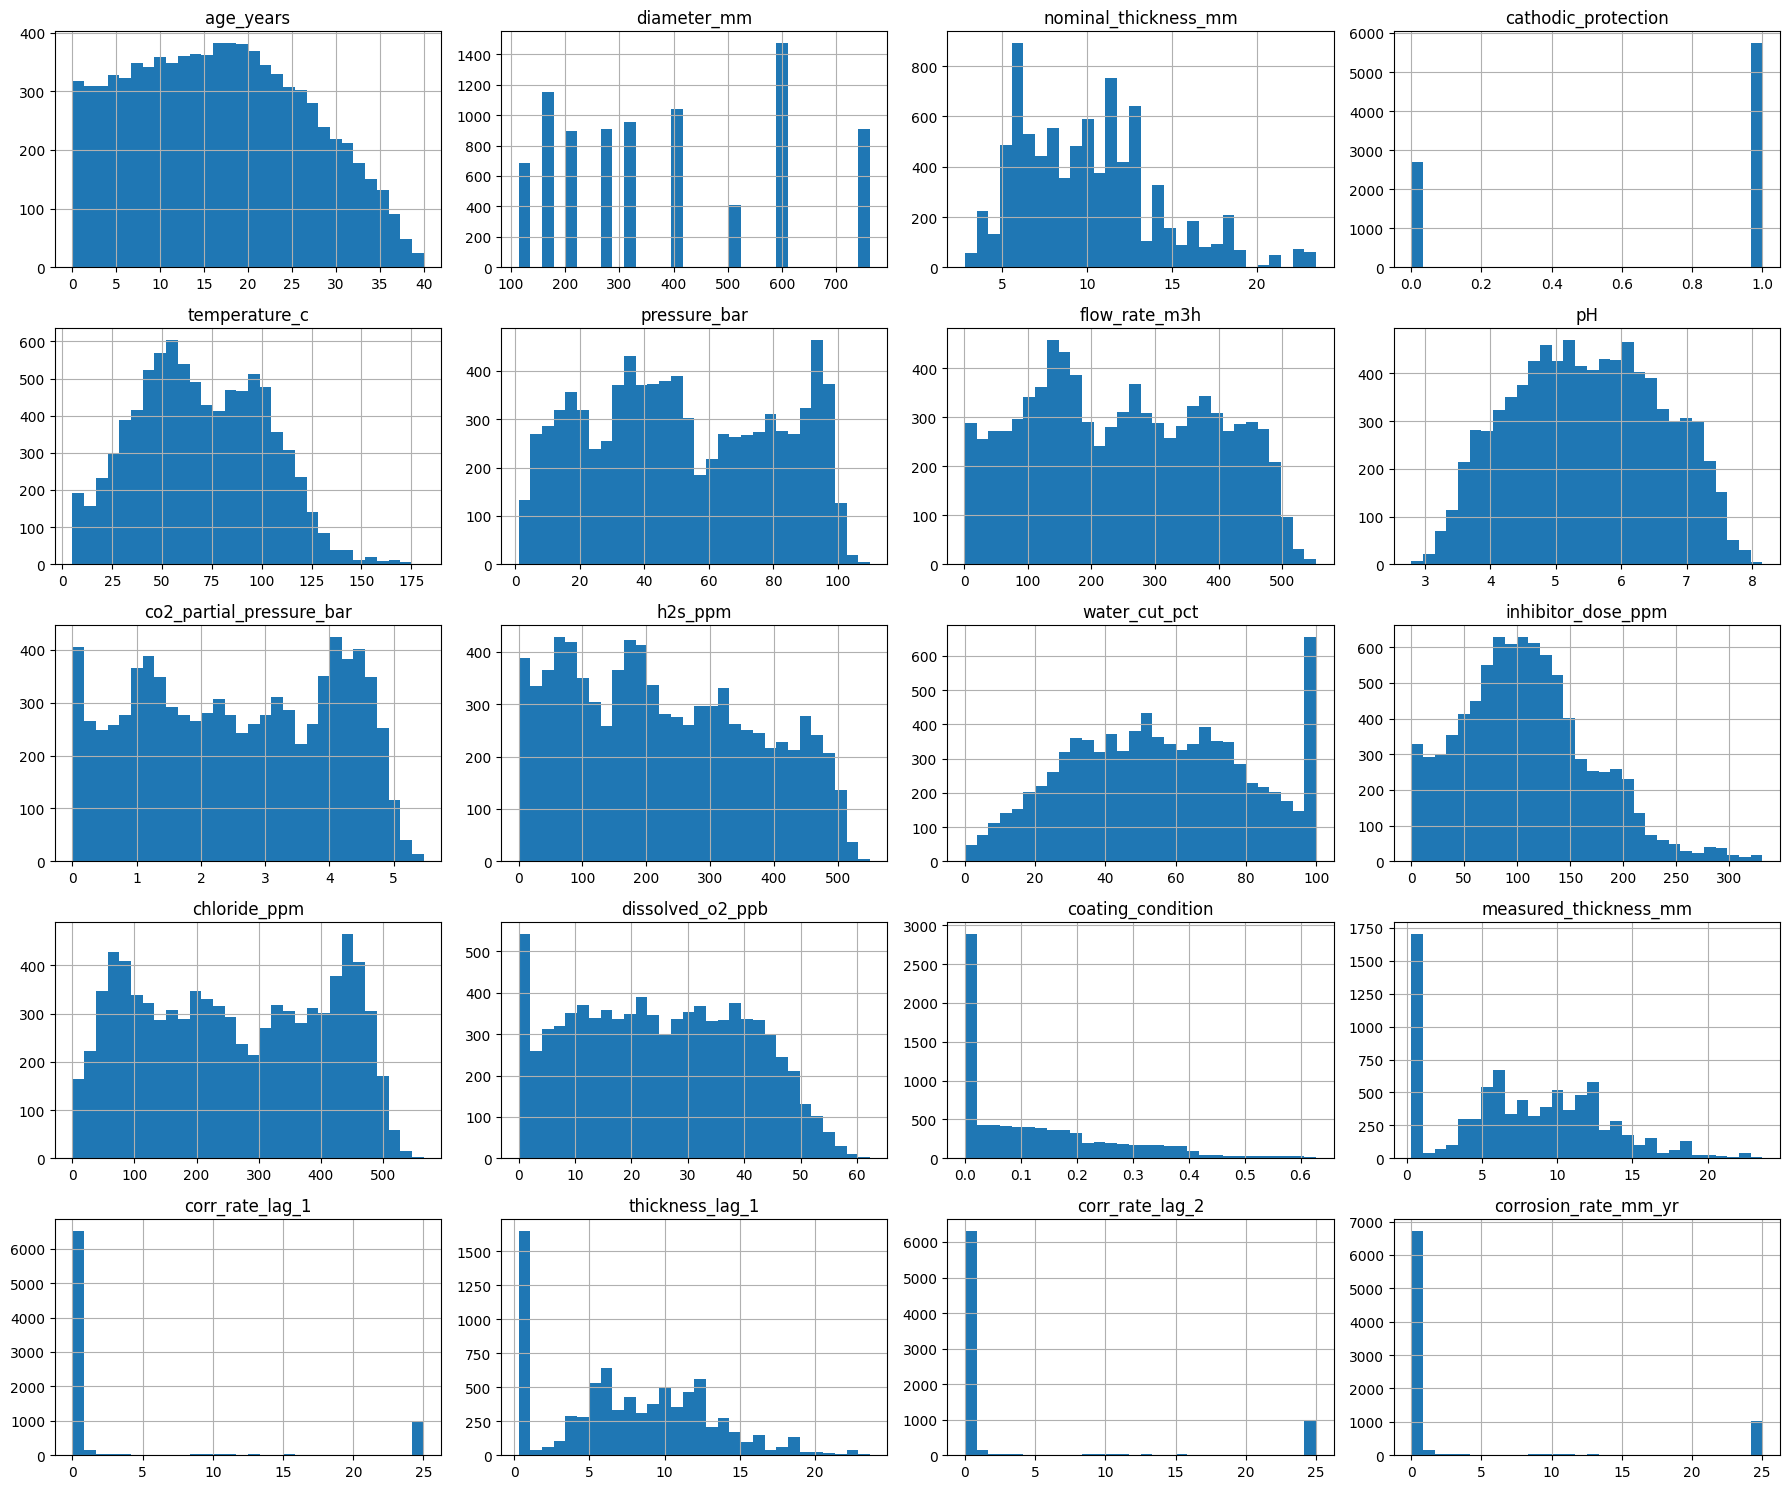

In [15]:
df1[numerical_columns].hist(figsize=(18, 15),bins=30)
plt.tight_layout()
plt.show()

#### Correlation Analysis

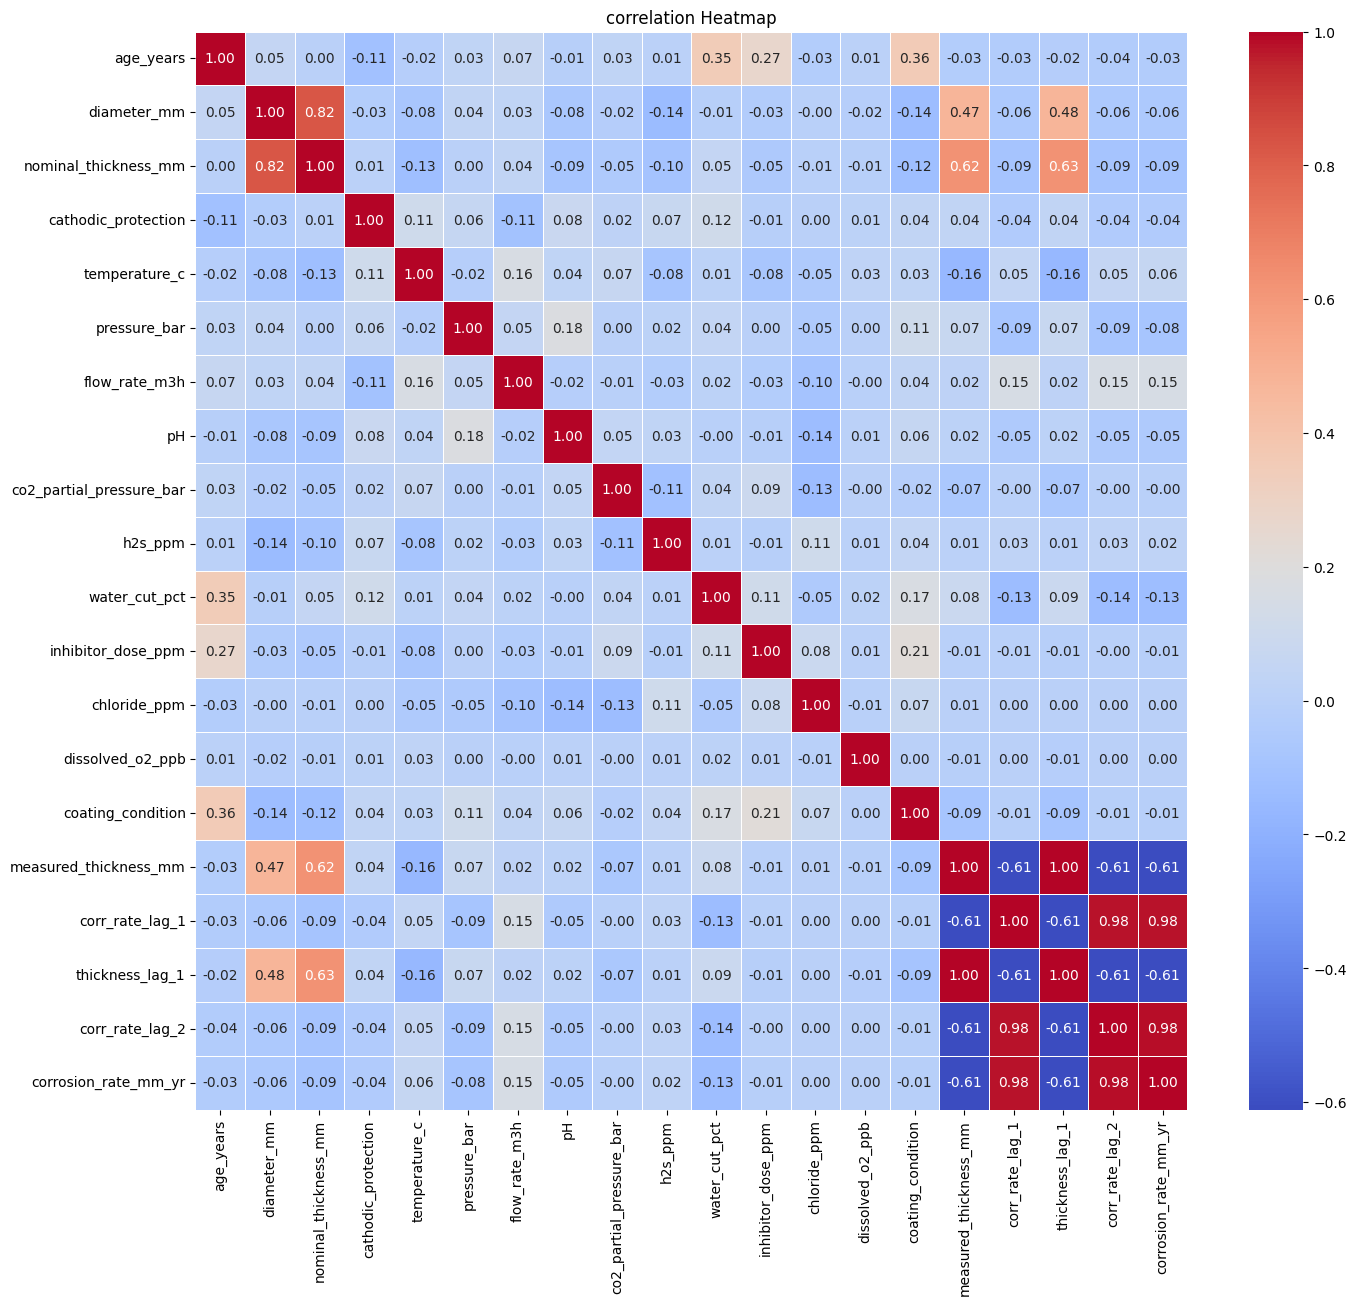

In [16]:
correlation=df1[numerical_columns].corr()
plt.figure(figsize=(16,14))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('correlation Heatmap')
plt.show()

#### Missing Value Analysis

In [17]:
df1.isnull().sum()

segment_id                    0
measurement_date              0
age_years                     0
material                      0
diameter_mm                   0
nominal_thickness_mm          0
coating_type                  0
cathodic_protection           0
fluid_type                    0
corrosion_mechanism           0
seam_type                     0
temperature_c                 0
pressure_bar                  0
flow_rate_m3h                 0
pH                            0
co2_partial_pressure_bar      0
h2s_ppm                       0
water_cut_pct                 0
inhibitor_dose_ppm            0
chloride_ppm                  0
dissolved_o2_ppb              0
coating_condition             0
measured_thickness_mm         0
corr_rate_lag_1             250
thickness_lag_1             250
corr_rate_lag_2             500
corrosion_rate_mm_yr          0
dtype: int64

In [18]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

                 Missing_Count  Missing_Percentage
corr_rate_lag_1            250            2.962085
thickness_lag_1            250            2.962085
corr_rate_lag_2            500            5.924171


#### Outlier Analysis

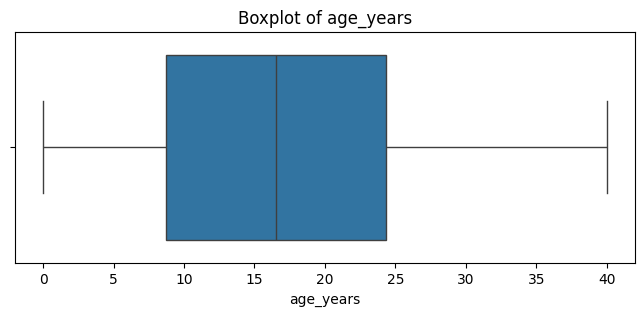

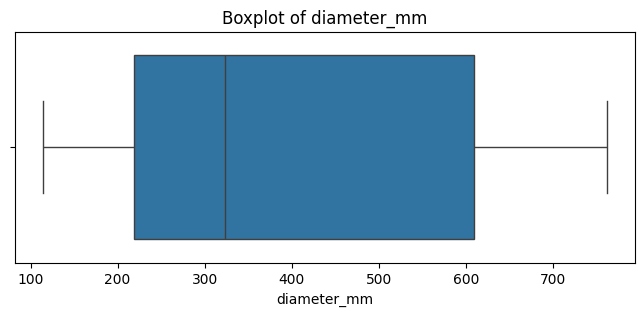

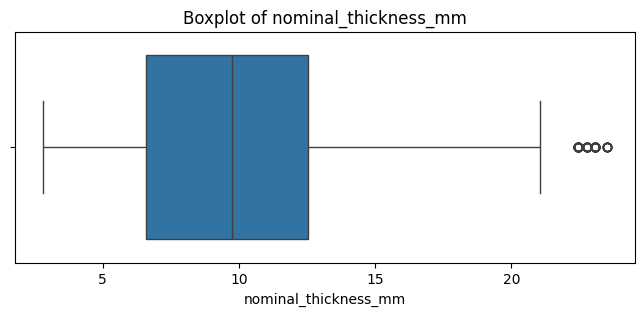

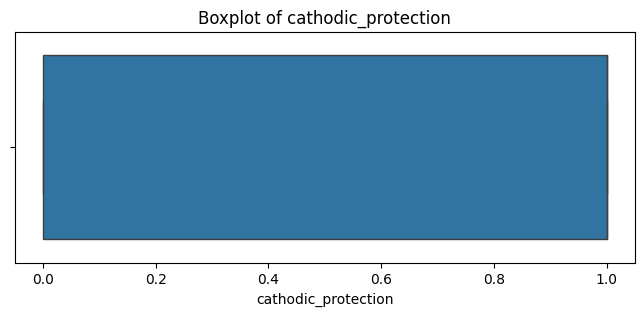

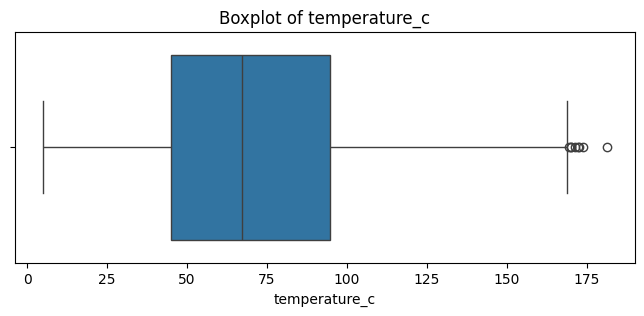

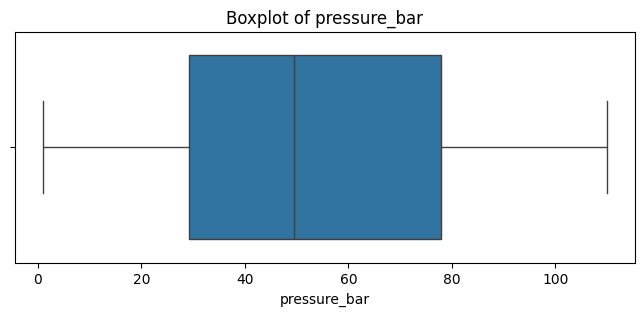

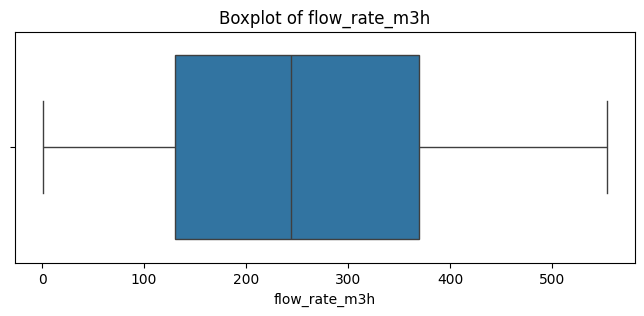

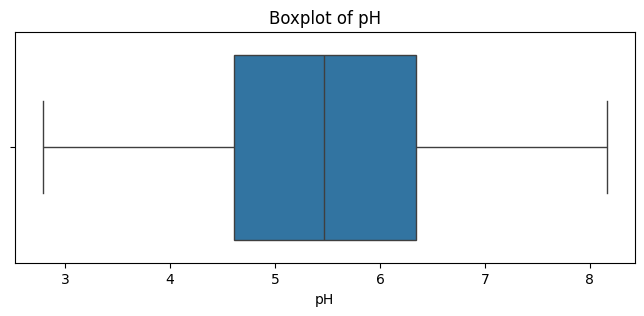

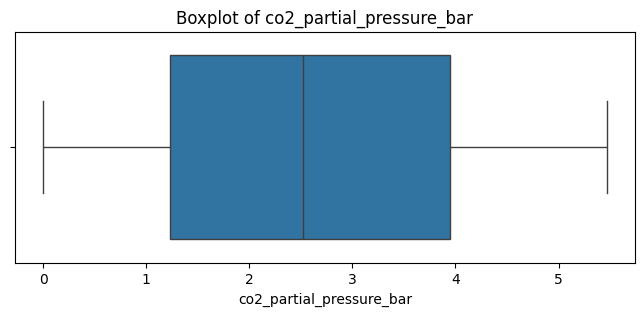

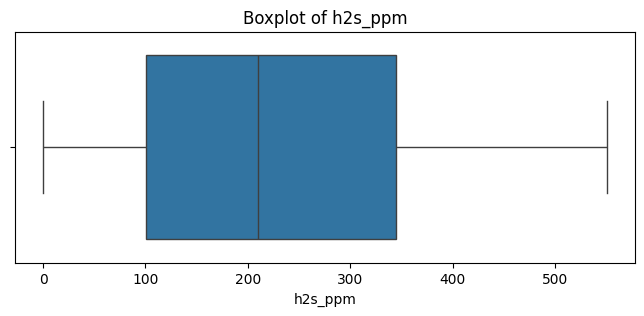

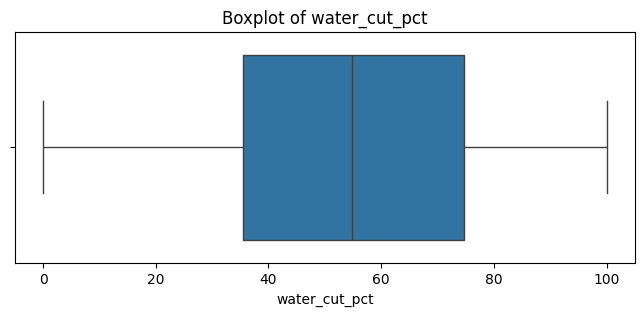

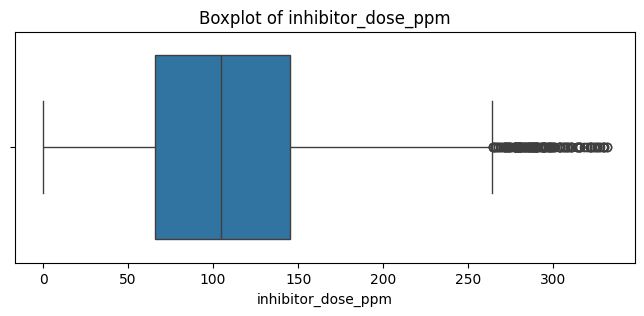

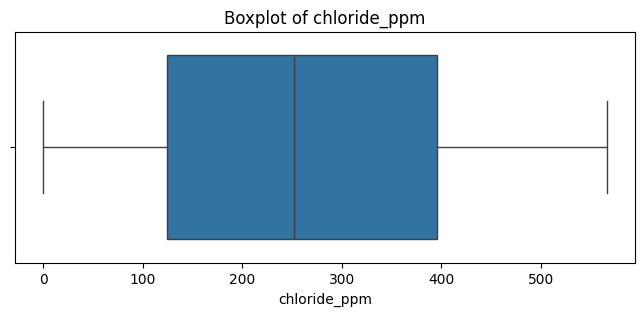

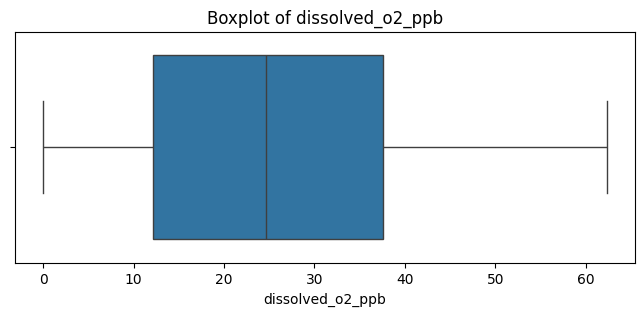

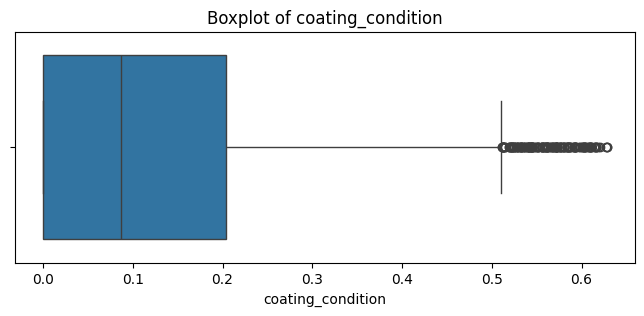

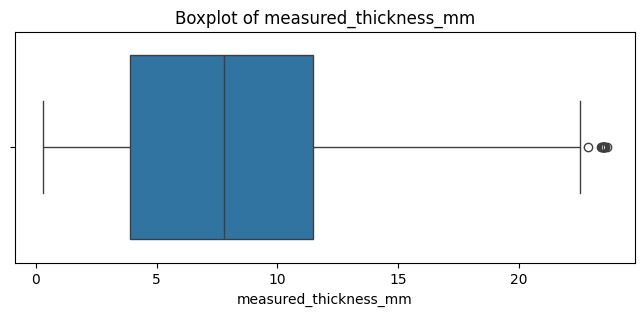

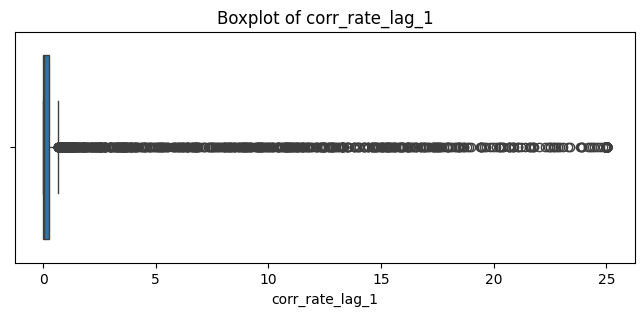

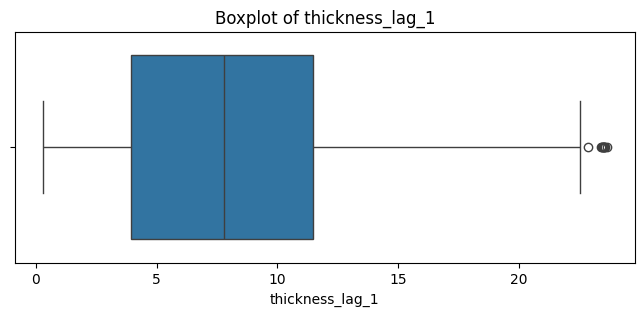

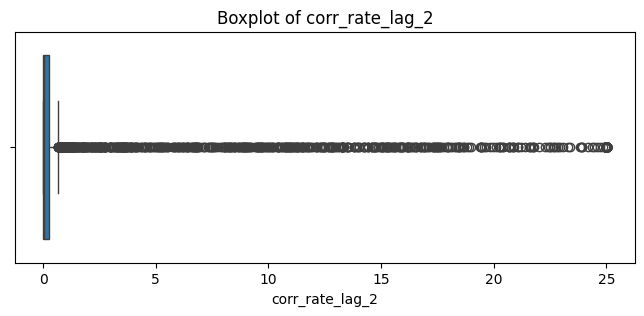

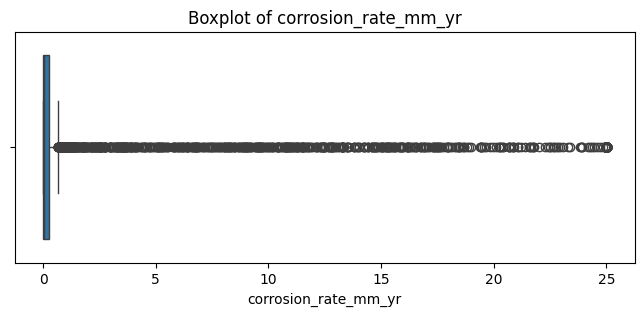

In [19]:
for col in numerical_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df1[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [20]:
for col in numerical_columns:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df1[col] < lower) |
             (df1[col] > upper)).sum()

    print(col, ":", count)

age_years : 0
diameter_mm : 0
nominal_thickness_mm : 133
cathodic_protection : 0
temperature_c : 8
pressure_bar : 0
flow_rate_m3h : 0
pH : 0
co2_partial_pressure_bar : 0
h2s_ppm : 0
water_cut_pct : 0
inhibitor_dose_ppm : 150
chloride_ppm : 0
dissolved_o2_ppb : 0
coating_condition : 158
measured_thickness_mm : 11
corr_rate_lag_1 : 1732
thickness_lag_1 : 10
corr_rate_lag_2 : 1676
corrosion_rate_mm_yr : 1780


In [21]:
check_cols = ['nominal_thickness_mm','inhibitor_dose_ppm','coating_condition','corr_rate_lag_1','corr_rate_lag_2','corrosion_rate_mm_yr']
for col in check_cols:
    print("\n", col)
    print(df1[col].describe())


 nominal_thickness_mm
count    8440.000000
mean       10.105521
std         4.101488
min         2.810000
25%         6.580000
50%         9.760000
75%        12.530000
max        23.500000
Name: nominal_thickness_mm, dtype: float64

 inhibitor_dose_ppm
count    8440.000000
mean      109.290960
std        61.703483
min         0.000000
25%        65.800000
50%       104.700000
75%       145.100000
max       331.400000
Name: inhibitor_dose_ppm, dtype: float64

 coating_condition
count    8440.000000
mean        0.127966
std         0.140011
min         0.000000
25%         0.000000
50%         0.087000
75%         0.204000
max         0.628000
Name: coating_condition, dtype: float64

 corr_rate_lag_1
count    8190.000000
mean        3.760962
std         8.411687
min         0.001000
25%         0.005900
50%         0.024800
75%         0.268800
max        25.015200
Name: corr_rate_lag_1, dtype: float64

 corr_rate_lag_2
count    7940.000000
mean        3.779124
std         8.432565
min

#### Target Variable Distribution

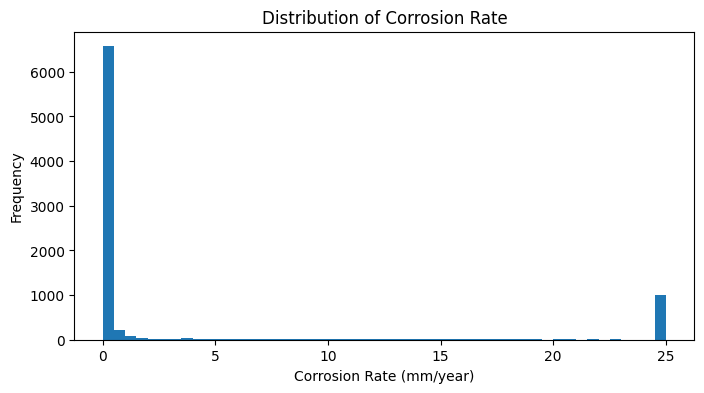

In [22]:
plt.figure(figsize=(8, 4))
plt.hist(df1['corrosion_rate_mm_yr'], bins=50)
plt.xlabel('Corrosion Rate (mm/year)')
plt.ylabel('Frequency')
plt.title('Distribution of Corrosion Rate')
plt.show()

#### Log-Transformed Target Distribution

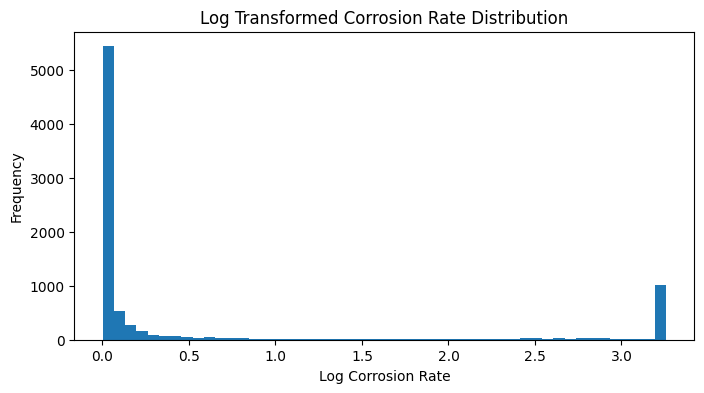

In [23]:
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df1['corrosion_rate_mm_yr']),bins=50)
plt.xlabel('Log Corrosion Rate')
plt.ylabel('Frequency')
plt.title('Log Transformed Corrosion Rate Distribution')
plt.show()

#### Material vs Corrosion Rate

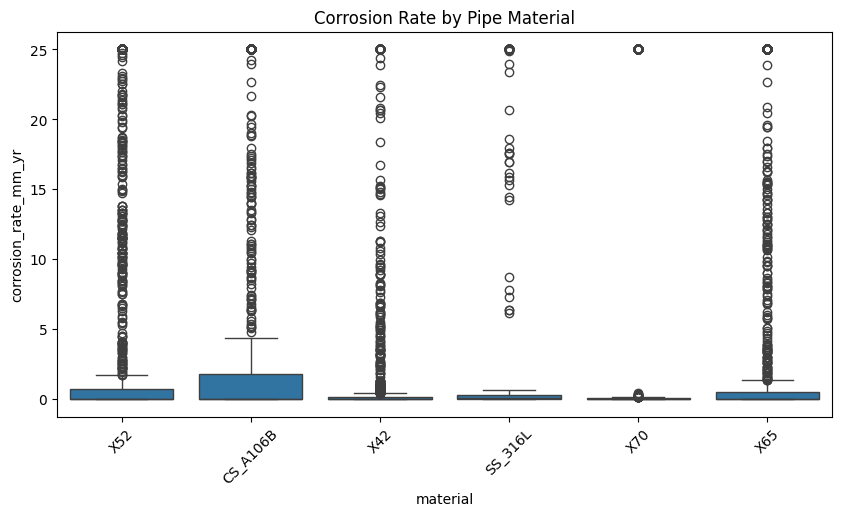

In [24]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df1,x='material',y='corrosion_rate_mm_yr')
plt.title('Corrosion Rate by Pipe Material')
plt.xticks(rotation=45)
plt.show()

#### Corrosion Mechanism vs Corrosion Rate

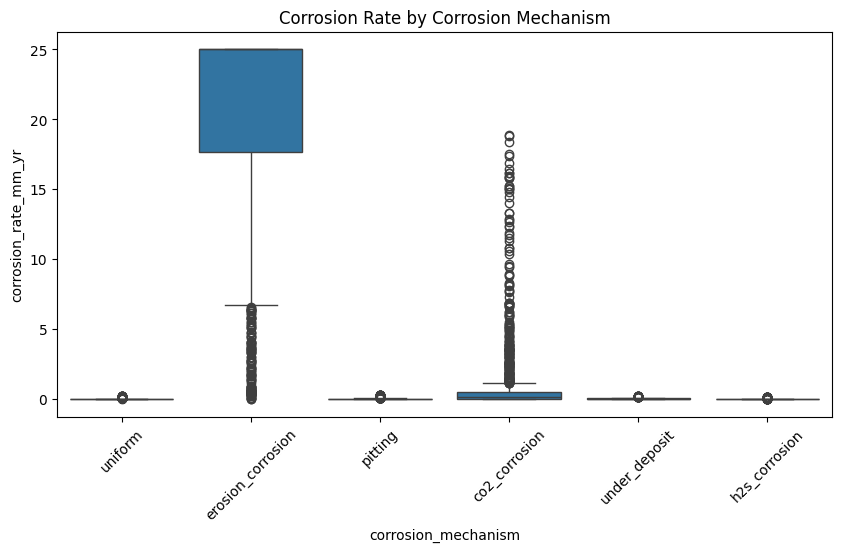

In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df1,x='corrosion_mechanism',y='corrosion_rate_mm_yr')
plt.title('Corrosion Rate by Corrosion Mechanism')
plt.xticks(rotation=45)
plt.show()

#### Temperature vs Corrosion Rate

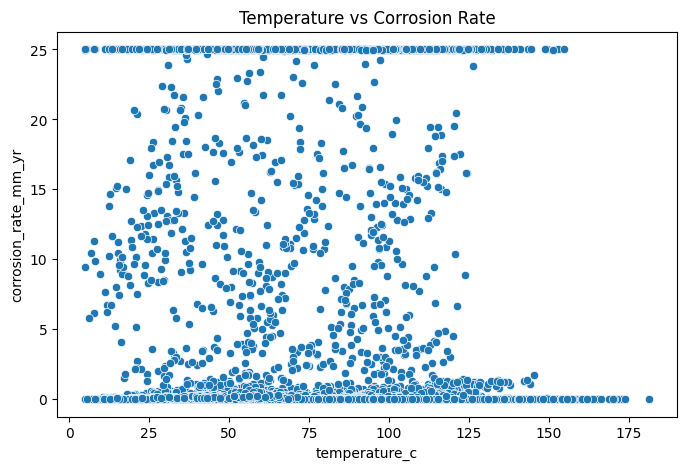

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df1,x='temperature_c',y='corrosion_rate_mm_yr')
plt.title('Temperature vs Corrosion Rate')
plt.show()

#### Pressure vs Corrosion Rate

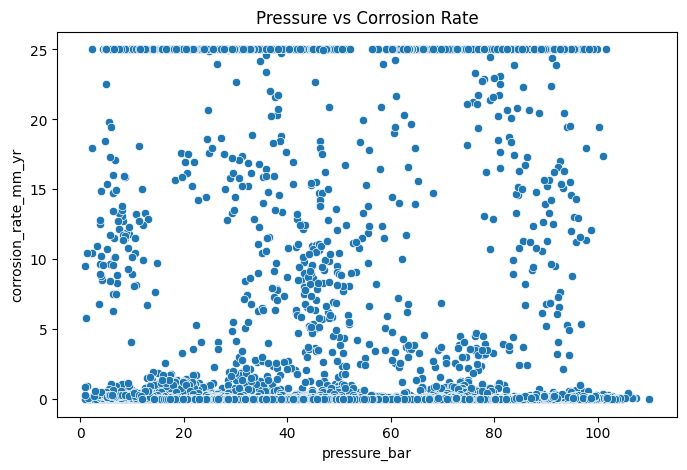

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df1,x='pressure_bar',y='corrosion_rate_mm_yr')
plt.title('Pressure vs Corrosion Rate')
plt.show()

## Data Cleaning and Preprocessing

#### Handling Missing Values

In [28]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

                 Missing_Count  Missing_Percentage
corr_rate_lag_1            250            2.962085
thickness_lag_1            250            2.962085
corr_rate_lag_2            500            5.924171


In [29]:
lag_cols = ['corr_rate_lag_1','thickness_lag_1','corr_rate_lag_2']

In [30]:
df_clean=df1.dropna(subset=lag_cols).copy()

In [31]:
print("Orginal shape:",df1.shape)
print("cleaned shape:",df_clean.shape)

Orginal shape: (8440, 27)
cleaned shape: (7940, 27)


In [32]:
df_clean.isnull().sum()

segment_id                  0
measurement_date            0
age_years                   0
material                    0
diameter_mm                 0
nominal_thickness_mm        0
coating_type                0
cathodic_protection         0
fluid_type                  0
corrosion_mechanism         0
seam_type                   0
temperature_c               0
pressure_bar                0
flow_rate_m3h               0
pH                          0
co2_partial_pressure_bar    0
h2s_ppm                     0
water_cut_pct               0
inhibitor_dose_ppm          0
chloride_ppm                0
dissolved_o2_ppb            0
coating_condition           0
measured_thickness_mm       0
corr_rate_lag_1             0
thickness_lag_1             0
corr_rate_lag_2             0
corrosion_rate_mm_yr        0
dtype: int64

In [33]:
num_cols=df_clean.select_dtypes(include=np.number).columns
num_cols

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')

In [34]:
correlation = df_clean[num_cols].corr()
correlation['corrosion_rate_mm_yr'].sort_values(ascending=False)

corrosion_rate_mm_yr        1.000000
corr_rate_lag_2             0.984598
corr_rate_lag_1             0.978638
flow_rate_m3h               0.157692
temperature_c               0.058789
h2s_ppm                     0.027307
chloride_ppm                0.002616
dissolved_o2_ppb            0.001909
co2_partial_pressure_bar   -0.005834
coating_condition          -0.010046
inhibitor_dose_ppm         -0.010240
age_years                  -0.035531
cathodic_protection        -0.043984
pH                         -0.048902
diameter_mm                -0.061611
pressure_bar               -0.085891
nominal_thickness_mm       -0.094649
water_cut_pct              -0.136778
measured_thickness_mm      -0.606834
thickness_lag_1            -0.608354
Name: corrosion_rate_mm_yr, dtype: float64

## Feature Selection and Engineering

#### Identifying the Target Variable

In [35]:
target="corrosion_rate_mm_yr"

#### Separating Features and Target

In [36]:
X = df_clean.drop(columns=[target, 'segment_id', 'measurement_date'])
y = df_clean[target]

In [37]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns

In [38]:
cat_cols

Index(['material', 'coating_type', 'fluid_type', 'corrosion_mechanism',
       'seam_type'],
      dtype='object')

#### Categorical Feature Encoding

In [39]:
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
bool_cols = X_encoded.select_dtypes(include='bool').columns
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)

In [40]:
print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)
X_encoded.head()

Original X shape: (7940, 24)
Encoded X shape: (7940, 38)


,age_years,diameter_mm,nominal_thickness_mm,cathodic_protection,temperature_c,pressure_bar,flow_rate_m3h,pH,co2_partial_pressure_bar,h2s_ppm,...,fluid_type_multiphase,fluid_type_produced_water,fluid_type_wet_gas,corrosion_mechanism_erosion_corrosion,corrosion_mechanism_h2s_corrosion,corrosion_mechanism_pitting,corrosion_mechanism_under_deposit,corrosion_mechanism_uniform,seam_type_SAW,seam_type_seamless
2,4.01,609.6,18.63,1,82.8,85.4,192.0,6.76,2.398,238.3,...,0,0,1,0,0,0,0,1,0,1
3,4.98,609.6,18.63,1,83.4,80.0,190.4,6.93,2.751,219.3,...,0,0,1,0,0,0,0,1,0,1
4,5.90,609.6,18.63,1,65.7,79.0,165.7,6.89,2.680,256.6,...,0,0,1,0,0,0,0,1,0,1
5,6.87,609.6,18.63,1,77.4,82.7,153.4,6.72,2.360,211.4,...,0,0,1,0,0,0,0,1,0,1
6,7.84,609.6,18.63,1,73.3,77.3,165.5,6.73,2.510,206.0,...,0,0,1,0,0,0,0,1,0,1


In [41]:
print(X_encoded.dtypes.value_counts())
X_encoded.head()

int64      20
float64    18
Name: count, dtype: int64


,age_years,diameter_mm,nominal_thickness_mm,cathodic_protection,temperature_c,pressure_bar,flow_rate_m3h,pH,co2_partial_pressure_bar,h2s_ppm,...,fluid_type_multiphase,fluid_type_produced_water,fluid_type_wet_gas,corrosion_mechanism_erosion_corrosion,corrosion_mechanism_h2s_corrosion,corrosion_mechanism_pitting,corrosion_mechanism_under_deposit,corrosion_mechanism_uniform,seam_type_SAW,seam_type_seamless
2,4.01,609.6,18.63,1,82.8,85.4,192.0,6.76,2.398,238.3,...,0,0,1,0,0,0,0,1,0,1
3,4.98,609.6,18.63,1,83.4,80.0,190.4,6.93,2.751,219.3,...,0,0,1,0,0,0,0,1,0,1
4,5.90,609.6,18.63,1,65.7,79.0,165.7,6.89,2.680,256.6,...,0,0,1,0,0,0,0,1,0,1
5,6.87,609.6,18.63,1,77.4,82.7,153.4,6.72,2.360,211.4,...,0,0,1,0,0,0,0,1,0,1
6,7.84,609.6,18.63,1,73.3,77.3,165.5,6.73,2.510,206.0,...,0,0,1,0,0,0,0,1,0,1


## Group-Based Train-Test Split

In [42]:
groups=df_clean['segment_id']
print(groups.head())
print("Unique pipeline segments:", groups.nunique())

2    SEG-0001
3    SEG-0001
4    SEG-0001
5    SEG-0001
6    SEG-0001
Name: segment_id, dtype: object
Unique pipeline segments: 250


In [43]:
from sklearn.model_selection import GroupShuffleSplit

In [44]:
split=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train,test=next(split.split(X_encoded,groups=groups))
X_train,X_test=X_encoded.iloc[train], X_encoded.iloc[test]
y_train,y_test=y.iloc[train], y.iloc[test]

In [45]:
print("train:", X_train.shape, y_train.shape)
print("test:", X_test.shape, y_test.shape)

train: (6484, 38) (6484,)
test: (1456, 38) (1456,)


## Baseline Model Development

In [46]:
from sklearn.ensemble import RandomForestRegressor

#### Random Forest with Historical Lag Features

In [47]:
rfg_model=RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
rfg_model.fit(X_train,y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


#### Baseline Model Evaluation

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [49]:
y_pred = rfg_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

#### Actual vs Predicted Corrosion Rate

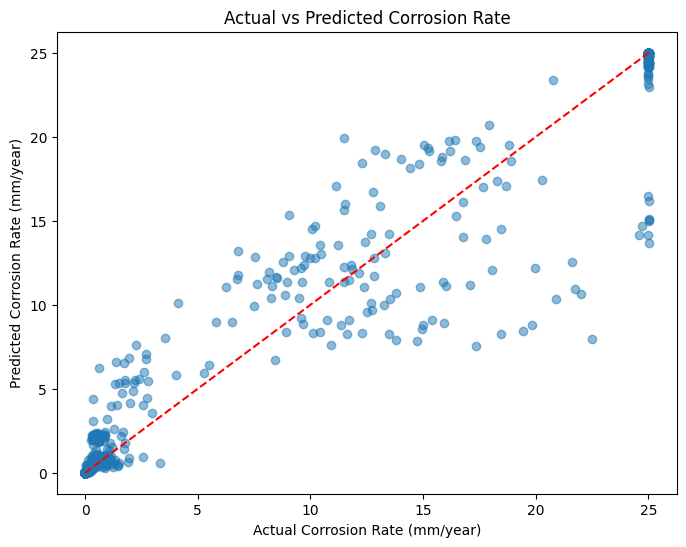

In [50]:
limits = [y_test.min(), y_test.max()]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot(limits, limits, "r--")

plt.xlabel("Actual Corrosion Rate (mm/year)")
plt.ylabel("Predicted Corrosion Rate (mm/year)")
plt.title("Actual vs Predicted Corrosion Rate")
plt.show()

#### Prediction Error Analysis

In [51]:
results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
results["Absolute_Error"] = (results["Actual"] - results["Predicted"]).abs()

print(results.nlargest(10, "Absolute_Error"))

       Actual  Predicted  Absolute_Error
7430  22.4988   7.964865       14.533935
3997  22.0264  10.638436       11.387964
7414  25.0035  13.696838       11.306662
7422  19.8319   8.817377       11.014523
7449  19.4278   8.414937       11.012863
3981  25.0001  14.150414       10.849686
3998  21.7371  10.930834       10.806266
5663  20.9035  10.373276       10.530224
3987  24.5853  14.182145       10.403155
7441  18.4655   8.271024       10.194476


In [52]:
largest_errors = results.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10)

In [53]:
error_details = df_clean.loc[
    largest_errors.index,
    [
        'segment_id',
        'measurement_date',
        'material',
        'corrosion_mechanism',
        'age_years',
        'measured_thickness_mm',
        'corr_rate_lag_1',
        'corr_rate_lag_2',
        'corrosion_rate_mm_yr'
    ]
]

print(error_details)

     segment_id measurement_date material corrosion_mechanism  age_years  \
7430   SEG-0223       2012-05-01      X52   erosion_corrosion      14.33   
3997   SEG-0121       2013-04-02      X52   erosion_corrosion       9.25   
7414   SEG-0223       2006-08-15      X52   erosion_corrosion       8.62   
7422   SEG-0223       2009-05-20      X52   erosion_corrosion      11.38   
7449   SEG-0223       2019-03-23      X52   erosion_corrosion      21.22   
3981   SEG-0121       2006-02-27      X52   erosion_corrosion       2.16   
3998   SEG-0121       2013-08-25      X52   erosion_corrosion       9.65   
5663   SEG-0174       2022-03-14      X52   erosion_corrosion       7.20   
3987   SEG-0121       2008-11-12      X52   erosion_corrosion       4.87   
7441   SEG-0223       2016-05-01      X52   erosion_corrosion      18.33   

      measured_thickness_mm  corr_rate_lag_1  corr_rate_lag_2  \
7430                  0.497          13.5119           9.6631   
3997                  0.726      

In [54]:
train_data = df_clean.loc[y_train.index]
test_data = df_clean.loc[y_test.index]

for name, target in [("Training", y_train), ("Testing", y_test)]:
    data = df_clean.loc[target.index]

    print(f"\n{name} data")
    print(data.groupby("corrosion_mechanism")["corrosion_rate_mm_yr"]
          .agg(["count", "mean", "median", "max"]))


Training data
                     count       mean    median      max
corrosion_mechanism                                     
co2_corrosion         1467   0.654649   0.11530  18.3458
erosion_corrosion     1069  22.066268  24.99820  25.0152
h2s_corrosion         1343   0.014009   0.00590   0.1423
pitting               1568   0.033653   0.01515   0.3107
under_deposit          277   0.039898   0.02530   0.2179
uniform                760   0.015528   0.00590   0.2520

Testing data
                     count       mean    median      max
corrosion_mechanism                                     
co2_corrosion          284   1.439519   0.21595  18.8976
erosion_corrosion      301  15.535164  17.08500  25.0129
h2s_corrosion          326   0.007935   0.00510   0.0426
pitting                255   0.029724   0.01630   0.3229
under_deposit           44   0.013614   0.00905   0.0430
uniform                246   0.017769   0.01090   0.1264


In [55]:
# Training: erosion-corrosion by segment
train_erosion = train_data[
    train_data['corrosion_mechanism'] == 'erosion_corrosion'
]

print("TRAINING SEGMENTS:")
print(
    train_erosion.groupby('segment_id')['corrosion_rate_mm_yr']
    .agg(['count', 'mean', 'median', 'max'])
    .sort_values('mean', ascending=False)
)

# Testing: erosion-corrosion by segment
test_erosion = test_data[
    test_data['corrosion_mechanism'] == 'erosion_corrosion'
]

print("\nTESTING SEGMENTS:")
print(
    test_erosion.groupby('segment_id')['corrosion_rate_mm_yr']
    .agg(['count', 'mean', 'median', 'max'])
    .sort_values('mean', ascending=False)
)

TRAINING SEGMENTS:
            count       mean    median      max
segment_id                                     
SEG-0175       37  25.001473  25.00130  25.0119
SEG-0075       31  25.001258  25.00160  25.0090
SEG-0072       33  25.001218  25.00210  25.0093
SEG-0179       26  25.001192  25.00045  25.0098
SEG-0227       33  25.000791  25.00070  25.0092
SEG-0111       35  25.000623  25.00030  25.0137
SEG-0079       47  25.000589  25.00010  25.0118
SEG-0243       40  25.000383  25.00040  25.0117
SEG-0066       36  25.000328  24.99925  25.0127
SEG-0161       41  25.000322  25.00000  25.0152
SEG-0209       52  25.000271  24.99975  25.0125
SEG-0103       35  25.000120  25.00120  25.0103
SEG-0228       37  24.999857  24.99960  25.0100
SEG-0018       41  24.999820  25.00000  25.0078
SEG-0002       37  24.999751  25.00050  25.0122
SEG-0053       48  24.999358  24.99915  25.0078
SEG-0048       30  24.999123  24.99820  25.0083
SEG-0099        9  24.999022  24.99950  25.0064
SEG-0093       33  24

In [56]:
# Training: erosion-corrosion by segment
train_erosion = train_data[
    train_data['corrosion_mechanism'] == 'erosion_corrosion'
]

print("TRAINING SEGMENTS:")
print(
    train_erosion.groupby('segment_id')['corrosion_rate_mm_yr']
    .agg(['count', 'mean', 'median', 'max'])
    .sort_values('mean', ascending=False)
)

# Testing: erosion-corrosion by segment
test_erosion = test_data[
    test_data['corrosion_mechanism'] == 'erosion_corrosion'
]

print("\nTESTING SEGMENTS:")
print(
    test_erosion.groupby('segment_id')['corrosion_rate_mm_yr']
    .agg(['count', 'mean', 'median', 'max'])
    .sort_values('mean', ascending=False)
)

TRAINING SEGMENTS:
            count       mean    median      max
segment_id                                     
SEG-0175       37  25.001473  25.00130  25.0119
SEG-0075       31  25.001258  25.00160  25.0090
SEG-0072       33  25.001218  25.00210  25.0093
SEG-0179       26  25.001192  25.00045  25.0098
SEG-0227       33  25.000791  25.00070  25.0092
SEG-0111       35  25.000623  25.00030  25.0137
SEG-0079       47  25.000589  25.00010  25.0118
SEG-0243       40  25.000383  25.00040  25.0117
SEG-0066       36  25.000328  24.99925  25.0127
SEG-0161       41  25.000322  25.00000  25.0152
SEG-0209       52  25.000271  24.99975  25.0125
SEG-0103       35  25.000120  25.00120  25.0103
SEG-0228       37  24.999857  24.99960  25.0100
SEG-0018       41  24.999820  25.00000  25.0078
SEG-0002       37  24.999751  25.00050  25.0122
SEG-0053       48  24.999358  24.99915  25.0078
SEG-0048       30  24.999123  24.99820  25.0083
SEG-0099        9  24.999022  24.99950  25.0064
SEG-0093       33  24

In [57]:
# Add corrosion mechanism to the prediction results
results['Mechanism'] = df_clean.loc[
    results.index, 'corrosion_mechanism'
]

# Calculate prediction error by mechanism
results['Error'] = (
    results['Actual'] - results['Predicted']
)

mechanism_performance = results.groupby('Mechanism').agg(
    Count=('Actual', 'count'),
    MAE=('Absolute_Error', 'mean'),
    Actual_Mean=('Actual', 'mean'),
    Predicted_Mean=('Predicted', 'mean')
)

print(mechanism_performance)

                   Count       MAE  Actual_Mean  Predicted_Mean
Mechanism                                                      
co2_corrosion        284  0.454543     1.439519        1.741221
erosion_corrosion    301  2.203937    15.535164       15.340133
h2s_corrosion        326  0.005022     0.007935        0.011040
pitting              255  0.013207     0.029724        0.031555
under_deposit         44  0.003858     0.013614        0.014220
uniform              246  0.007526     0.017769        0.022106


In [58]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rfg_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

                                  Feature  Importance
18                        corr_rate_lag_2    0.957005
16                        corr_rate_lag_1    0.021492
6                           flow_rate_m3h    0.004525
11                     inhibitor_dose_ppm    0.002963
7                                      pH    0.002535
4                           temperature_c    0.002071
5                            pressure_bar    0.001222
0                               age_years    0.001034
10                          water_cut_pct    0.000933
9                                 h2s_ppm    0.000890
8                co2_partial_pressure_bar    0.000788
12                           chloride_ppm    0.000585
13                       dissolved_o2_ppb    0.000551
17                        thickness_lag_1    0.000509
31  corrosion_mechanism_erosion_corrosion    0.000487


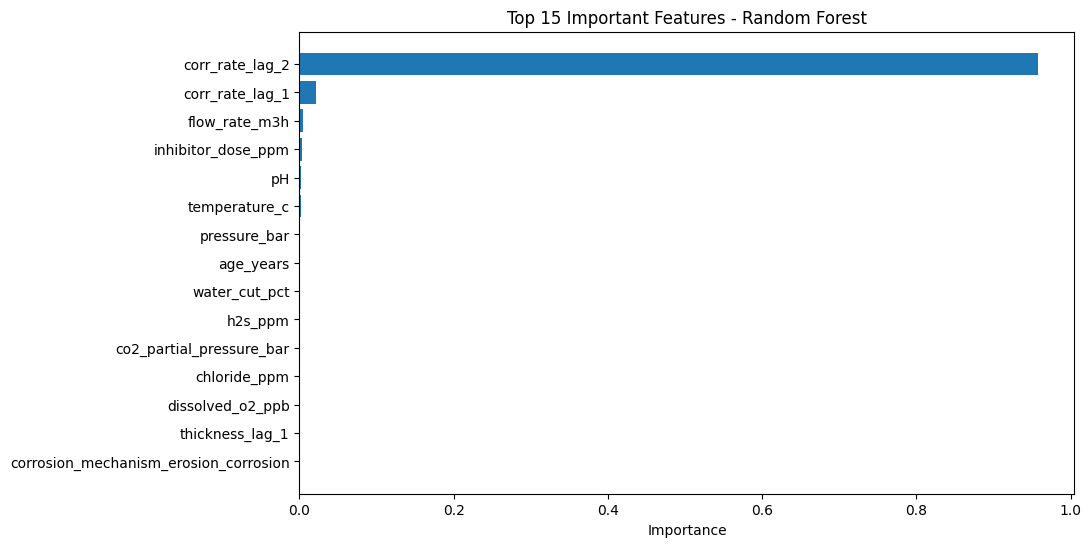

In [59]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(15)['Feature'][::-1],
    feature_importance.head(15)['Importance'][::-1]
)

plt.xlabel("Importance")
plt.title("Top 15 Important Features - Random Forest")
plt.show()

## Machine Learning Model Development Without Historical Lag Features

In [60]:
lag_features = ['corr_rate_lag_1','corr_rate_lag_2','thickness_lag_1']
X_no_lag = X.drop(columns=lag_features)
cat_cols = X_no_lag.select_dtypes(include=['object', 'category']).columns

In [61]:
X_no_lag_encoded = pd.get_dummies(X_no_lag,columns=cat_cols,drop_first=True)
bool_cols = X_no_lag_encoded.select_dtypes(include='bool').columns

X_no_lag_encoded[bool_cols] = (X_no_lag_encoded[bool_cols].astype(int))


In [62]:
X_train_no_lag = X_no_lag_encoded.loc[X_train.index]
X_test_no_lag = X_no_lag_encoded.loc[X_test.index]

rf_no_lag = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
rf_no_lag.fit(X_train_no_lag, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [63]:
y_pred_no_lag = rf_no_lag.predict(X_test_no_lag)

In [64]:
print("MAE:", mean_absolute_error(y_test, y_pred_no_lag))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_no_lag)))
print("R2:", r2_score(y_test, y_pred_no_lag))

MAE: 1.4131940776098897
RMSE: 3.393687609500818
R2: 0.8085035180747727


## Machine Learning Model Comparison

In [65]:
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        max_depth=6,
        random_state=42
    )
}

results_comparison = []

for name, model in models.items():

    model.fit(X_train_no_lag, y_train)

    predictions = model.predict(X_test_no_lag)

    results_comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results_comparison)

comparison_df.sort_values(
    by="R2",
    ascending=False
)

,Model,MAE,RMSE,R2
3,Hist Gradient Boosting,1.196456,3.067600,0.843536
2,Gradient Boosting,1.316898,3.184087,0.831427
0,Random Forest,1.434742,3.501941,0.796092
1,Extra Trees,1.471455,4.034885,0.729306


## Hyperparameter Tuning Using GroupKFold Cross-Validation

In [66]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

hgb = HistGradientBoostingRegressor(
    random_state=42
)

param_grid = {
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_iter": [100, 150, 200, 300],
    "max_leaf_nodes": [15, 20, 31, 40],
    "max_depth": [None, 5, 8, 10],
    "min_samples_leaf": [10, 20, 30, 50],
    "l2_regularization": [0, 0.1, 1, 5]
}

random_search = RandomizedSearchCV(
    estimator=hgb,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_no_lag, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV RMSE:")
print(-random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'min_samples_leaf': 20, 'max_leaf_nodes': 20, 'max_iter': 200, 'max_depth': None, 'learning_rate': 0.1, 'l2_regularization': 1}
Best CV RMSE:
2.2642776003274814


## Final Model Evaluation

In [67]:

best_model = random_search.best_estimator_

# Predict on unseen test data
y_pred_tuned = best_model.predict(X_test_no_lag)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred_tuned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Hist Gradient Boosting Results")
print("------------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Tuned Hist Gradient Boosting Results
------------------------------------
MAE: 1.2531919424080142
RMSE: 3.0658921433959847
R2 Score: 0.8437101338821872


In [68]:
import joblib

joblib.dump(best_model, "hist_gradient_boosting_model.pkl")

['hist_gradient_boosting_model.pkl']

## Explainable AI Using SHAP

In [69]:
import shap

print("SHAP version:", shap.__version__)

C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.49.1


In [70]:
# Best tuned model
final_model = random_search.best_estimator_

# Background dataset for SHAP
background = X_train_no_lag.sample(
    n=min(50, len(X_train_no_lag)),
    random_state=42
)

# Select test samples for explanation
X_shap = X_test_no_lag.sample(
    n=min(50, len(X_test_no_lag)),
    random_state=42
)

In [71]:
explainer = shap.Explainer(
    final_model.predict,
    background,
    algorithm="permutation"
)

shap_values = explainer(
    X_shap,
    max_evals=2 * X_train_no_lag.shape[1] + 1
)

PermutationExplainer explainer: 51it [00:11,  2.88it/s]                        


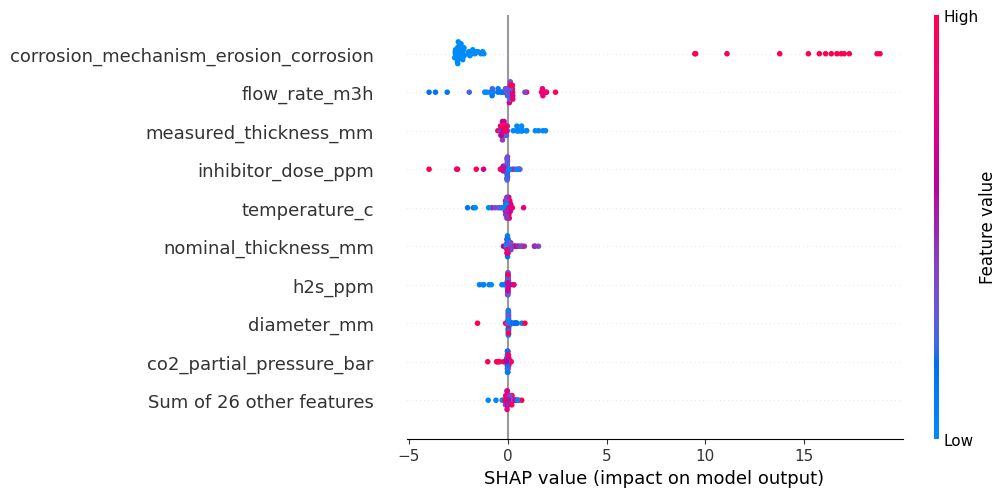

In [72]:
shap.plots.beeswarm(shap_values)

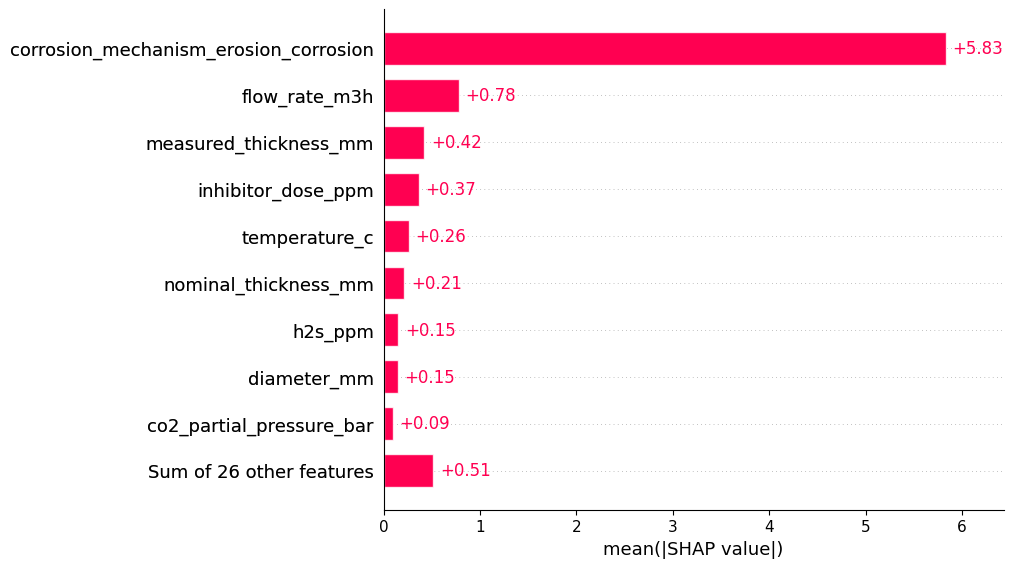

In [73]:
shap.plots.bar(shap_values)

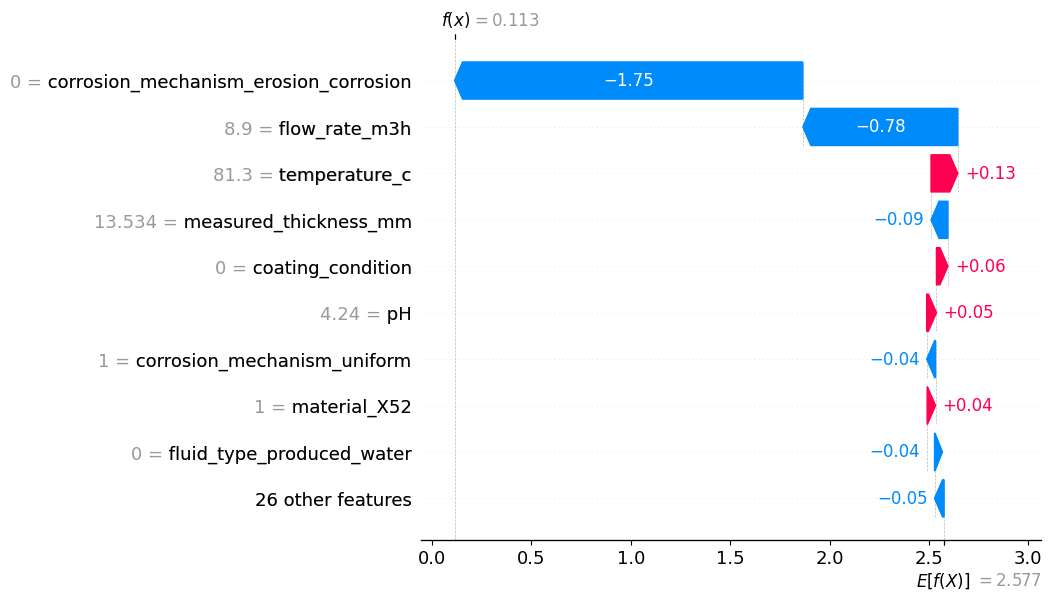

In [74]:
shap.plots.waterfall(shap_values[0])

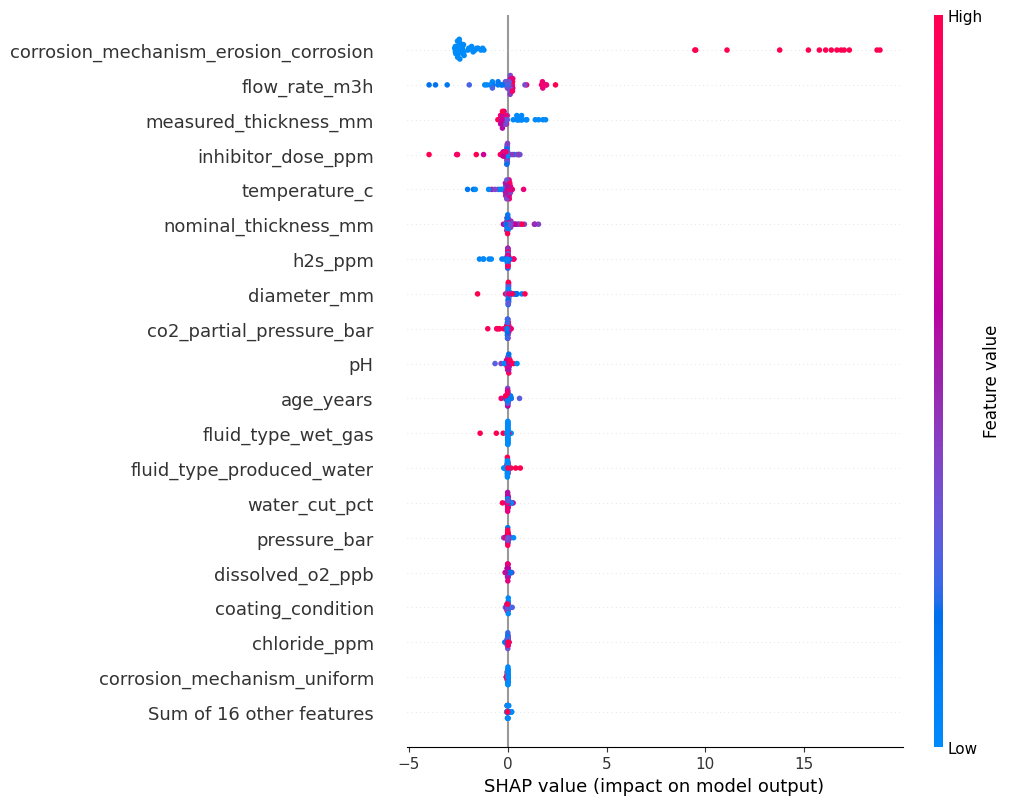

In [75]:
shap.plots.beeswarm(
    shap_values,
    max_display=20
)

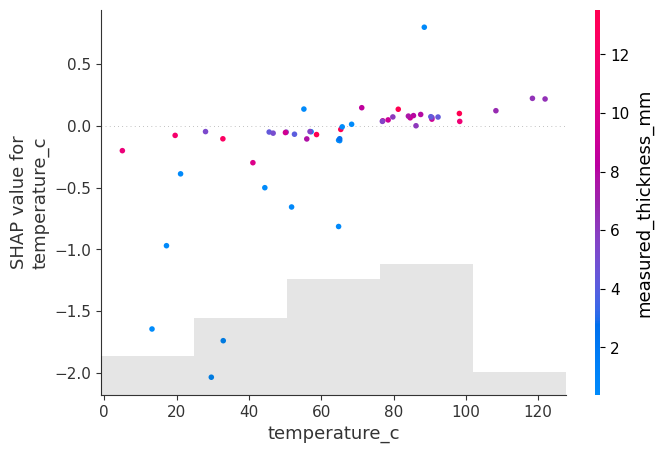

In [76]:
shap.plots.scatter(
    shap_values[:, "temperature_c"],
    color=shap_values
)

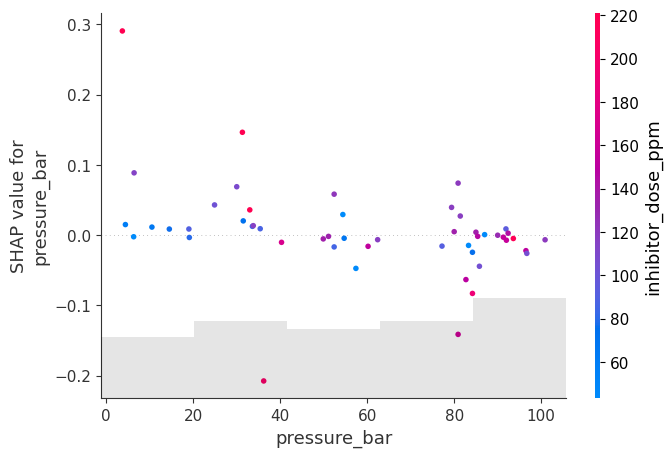

In [77]:
shap.plots.scatter(
    shap_values[:, "pressure_bar"],
    color=shap_values
)

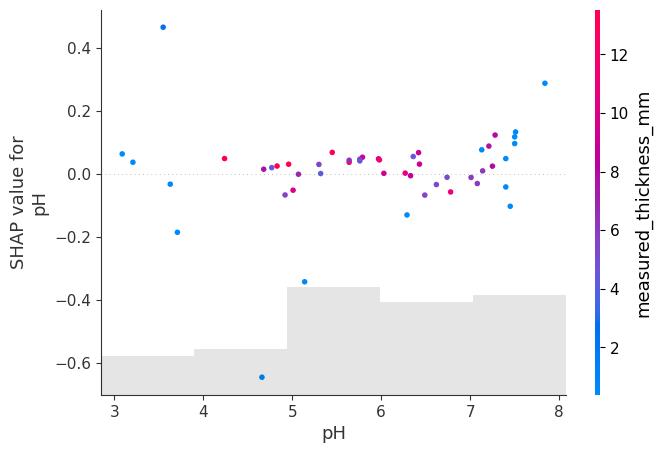

In [78]:
shap.plots.scatter(
    shap_values[:, "pH"],
    color=shap_values
)

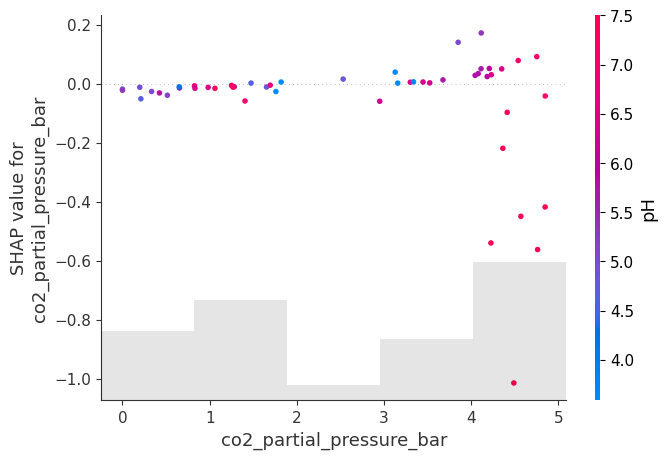

In [79]:
shap.plots.scatter(
    shap_values[:, "co2_partial_pressure_bar"],
    color=shap_values
)

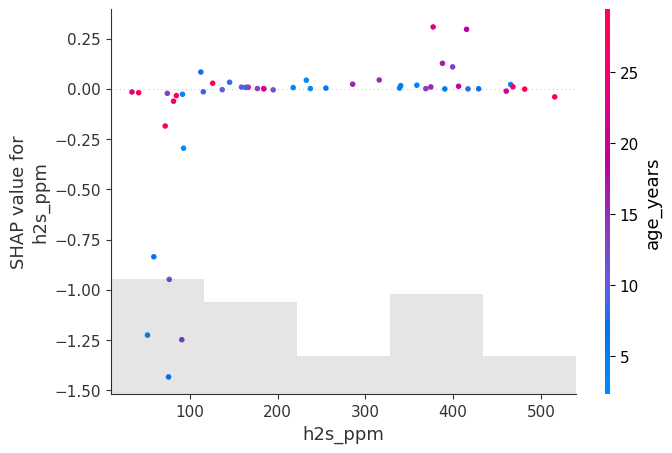

In [80]:
shap.plots.scatter(
    shap_values[:, "h2s_ppm"],
    color=shap_values
)

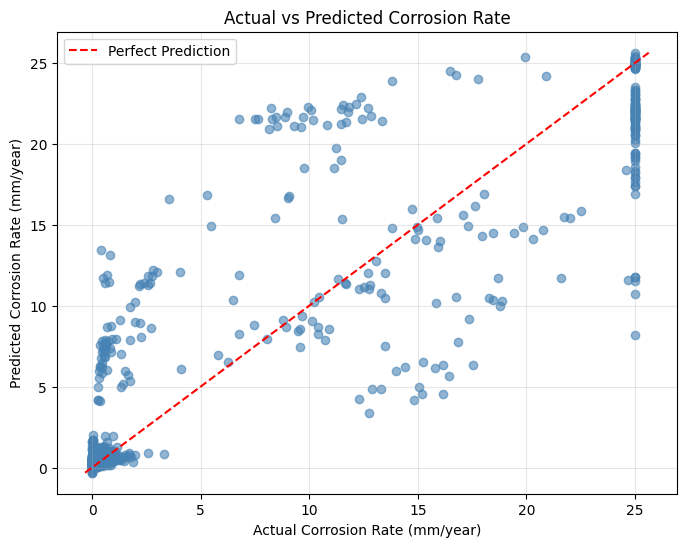

In [81]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_tuned,
    alpha=0.6,
    color="steelblue"
)

min_val = min(y_test.min(), y_pred_tuned.min())
max_val = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Corrosion Rate (mm/year)")
plt.ylabel("Predicted Corrosion Rate (mm/year)")
plt.title("Actual vs Predicted Corrosion Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

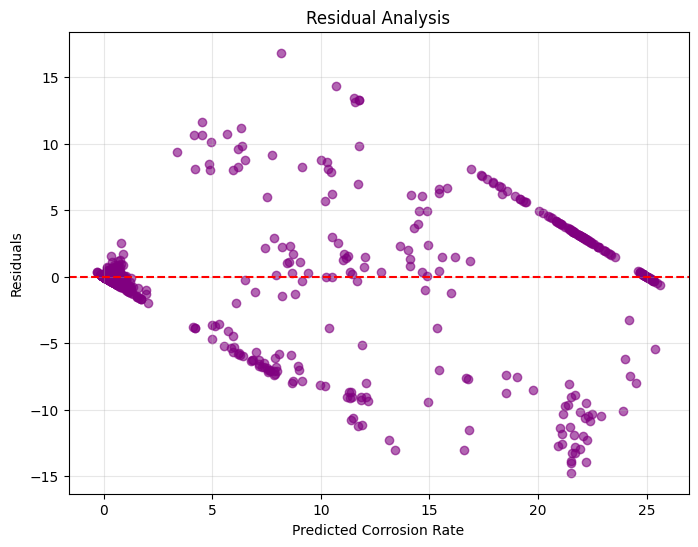

In [82]:
residuals = y_test - y_pred_tuned

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_tuned,
    residuals,
    alpha=0.6,
    color="purple"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Corrosion Rate")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.grid(alpha=0.3)
plt.show()

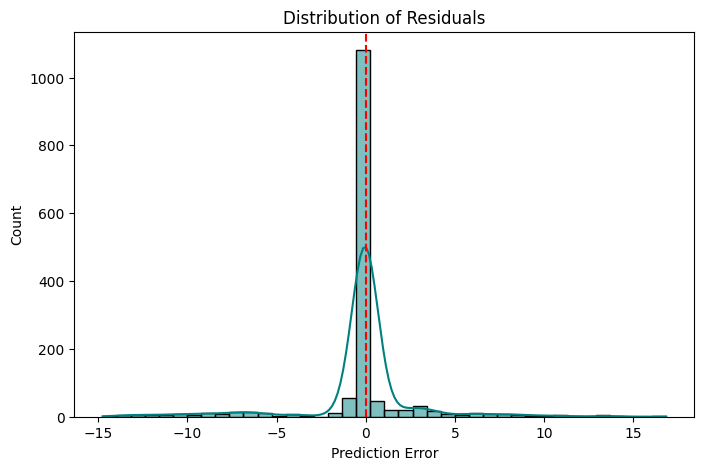

In [83]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True,
    color="teal"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Prediction Error")
plt.title("Distribution of Residuals")
plt.show()